<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D1%805_%D0%94%D1%83%D0%B4%D0%B0%D1%80%D0%B5%D1%86%D1%8C_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)


In [2]:
import kagglehub

path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print("Шлях до завантаженого датасету:", path)
print("Файли у директорії:", os.listdir(path))


Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Шлях до завантаженого датасету: /kaggle/input/daily-climate-time-series-data-delhi-india
Файли у директорії: ['kaggel_weather_2013_to_2024.csv']


In [3]:
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
csv_path = os.path.join(path, "kaggel_weather_2013_to_2024.csv") if "kaggel_weather_2013_to_2024.csv" in csv_files else os.path.join(path, csv_files[0])

df = pd.read_csv(csv_path)
print("Перші 5 рядків:")
display(df.head())

print("\nІнформація про датасет:")
df.info()

print("\nОписова статистика:")
display(df.describe(include="all"))


Перші 5 рядків:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622


Підготовка даних

In [4]:
# Автоматично визначаємо колонку з датою
date_col = next((c for c in df.columns if "date" in c.lower()), df.columns[0])

df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df = df.dropna(subset=[date_col]).sort_values(by=date_col).reset_index(drop=True)

# Видаляємо явні індексні/зайві колонки, якщо такі є (наприклад, Unnamed: 0)
extra_cols = [c for c in df.columns if "unnamed" in c.lower()]
if extra_cols:
    df = df.drop(columns=extra_cols)

# Перетворюємо числові колонки (крім дати)
for c in df.columns:
    if c != date_col:
        df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.set_index(date_col)
print("Новий індекс та перші рядки після сортування:")
display(df.head())


Новий індекс та перші рядки після сортування:


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
print("Розмір датасету (рядки, стовпці):", df.shape)
print("Період даних:", df.index.min(), "—", df.index.max())
df.info()


Розмір датасету (рядки, стовпці): (3557, 27)
Період даних: 2013-04-14 00:00:00 — 2024-11-30 00:00:00
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             0 non-null      fl

In [6]:
print("Кількість пропущених значень до обробки:")
print(df.isna().sum())

# Заповнюємо пропуски лінійною інтерполяцією у часі та крайовими значеннями
df = df.interpolate(method="time").ffill().bfill()

print("\nКількість пропущених значень після обробки:")
print(df.isna().sum())

# Визначаємо цільову колонку температури (пріоритет: meantemp / temp / temperature / перший числовий стовпець)
temp_col = next(
    (c for c in df.columns if any(k in c.lower() for k in ["meantemp", "mean_temp", "temp", "tavg"])),
    df.select_dtypes(include=[np.number]).columns[0]
)
print("\nОбрана колонка температури для аналізу та прогнозування:", temp_col)


Кількість пропущених значень до обробки:
tempmax                     0
tempmin                     0
temp                        0
feelslikemax                0
feelslikemin                0
feelslike                   0
humidity                    0
precip                      0
precipprob                  0
precipcover                 0
windspeed                   0
sealevelpressure            0
conditions               3557
Year                        0
month                       0
dayofweek                   0
dayofyear                   0
year-2000                   0
weekofyear                  0
tempmax_humidity            0
tempmin_humidity            0
temp_humidity               0
feelslikemax_humidity       0
feelslikemin_humidity       0
feelslike_humidity          0
temp_range                  0
heat_index                  0
dtype: int64

Кількість пропущених значень після обробки:
tempmax                     0
tempmin                     0
temp                        0
f

Графік температури

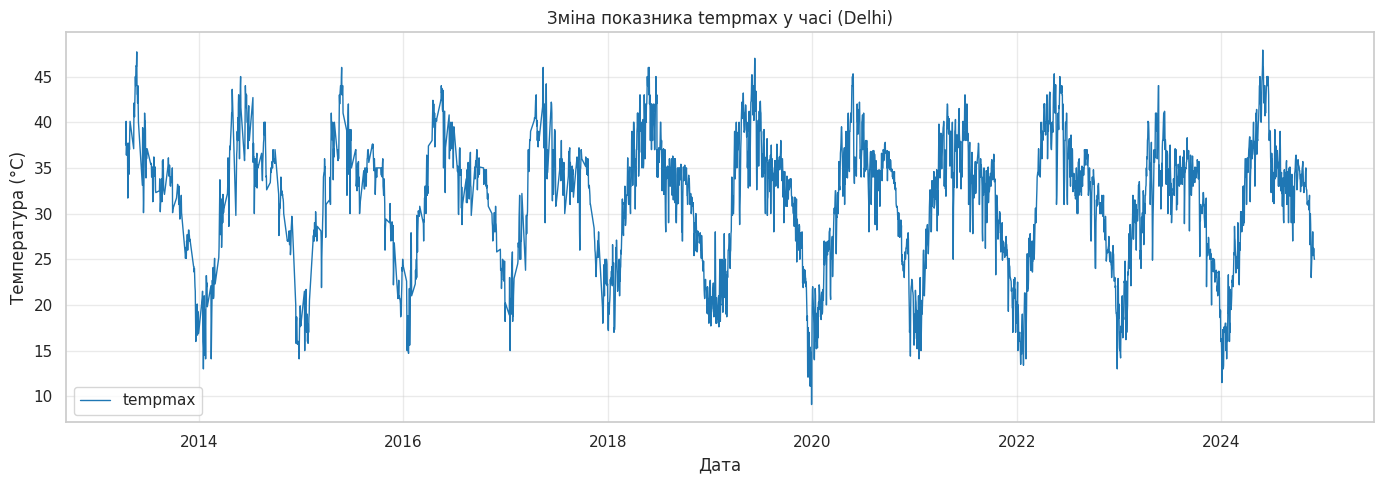

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], linewidth=1, color="tab:blue", label=temp_col)
plt.title(f"Зміна показника {temp_col} у часі (Delhi)")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


Ковзне середнє

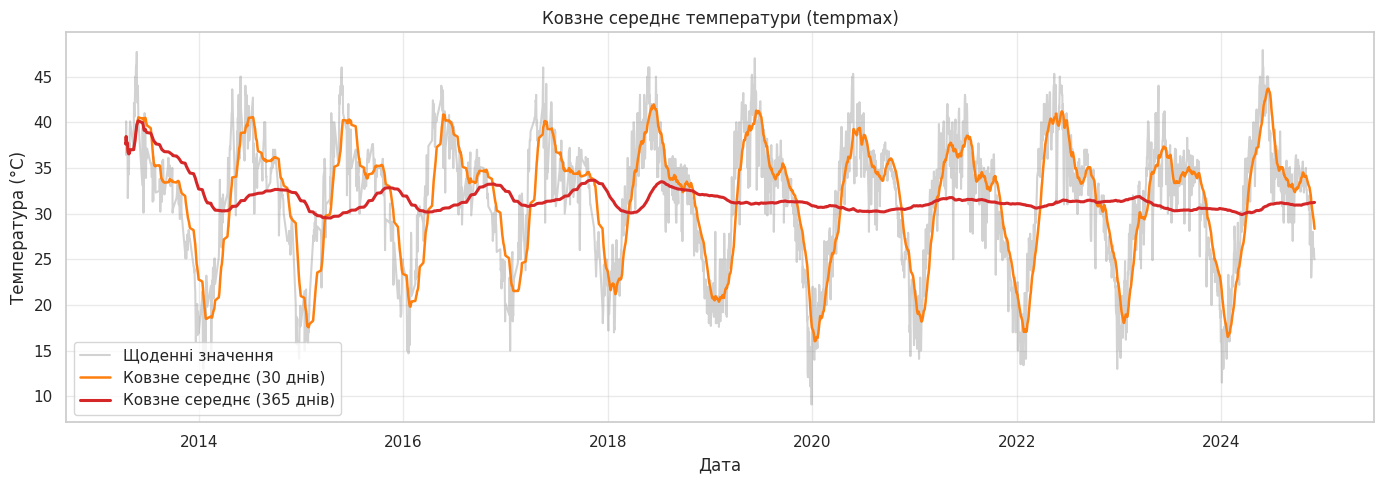

In [8]:
roll_30 = df[temp_col].rolling(window=30, min_periods=1).mean()
roll_365 = df[temp_col].rolling(window=365, min_periods=1).mean()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], alpha=0.35, color="gray", label="Щоденні значення")
plt.plot(df.index, roll_30, linewidth=1.8, color="tab:orange", label="Ковзне середнє (30 днів)")
plt.plot(df.index, roll_365, linewidth=2.2, color="tab:red", label="Ковзне середнє (365 днів)")
plt.title(f"Ковзне середнє температури ({temp_col})")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


Розподіл температури

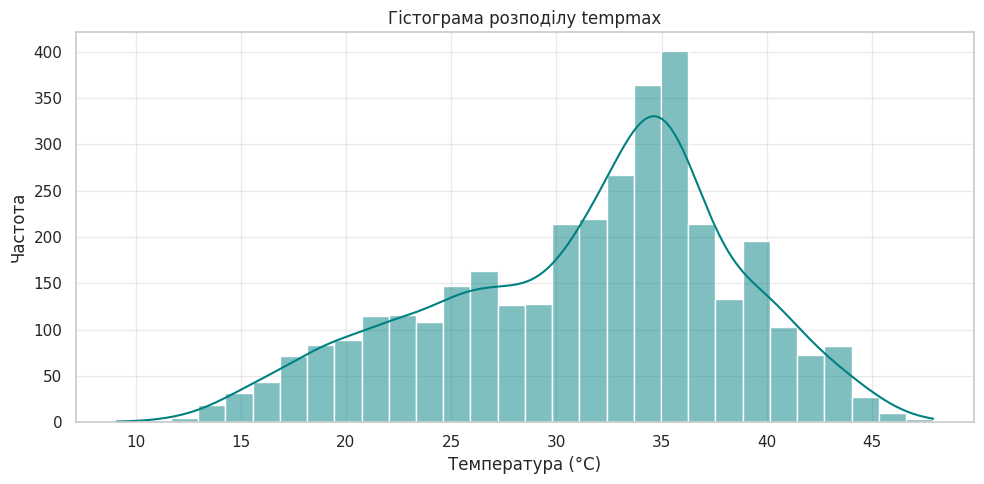

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df[temp_col], bins=30, kde=True, color="teal")
plt.title(f"Гістограма розподілу {temp_col}")
plt.xlabel("Температура (°C)")
plt.ylabel("Частота")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

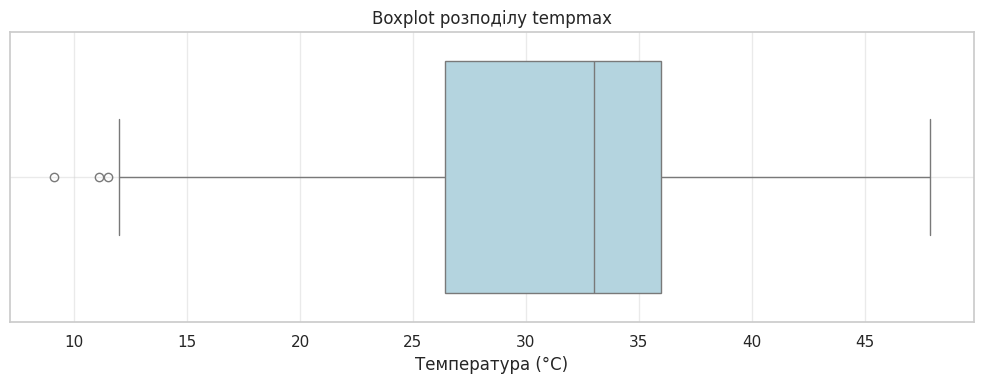

In [11]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[temp_col], color="lightblue")
plt.title(f"Boxplot розподілу {temp_col}")
plt.xlabel("Температура (°C)")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


Аналіз автокореляції
ACF

PACF

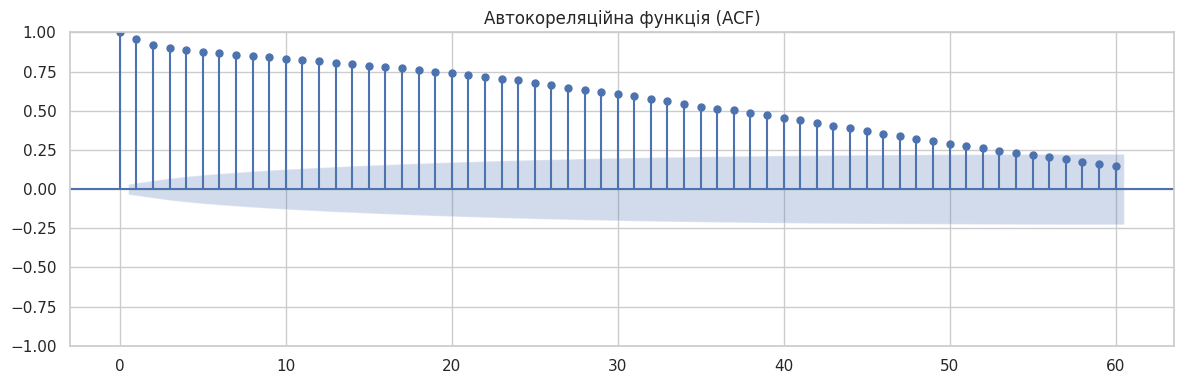

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df[temp_col], lags=60, ax=ax)
ax.set_title("Автокореляційна функція (ACF)")
plt.tight_layout()
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

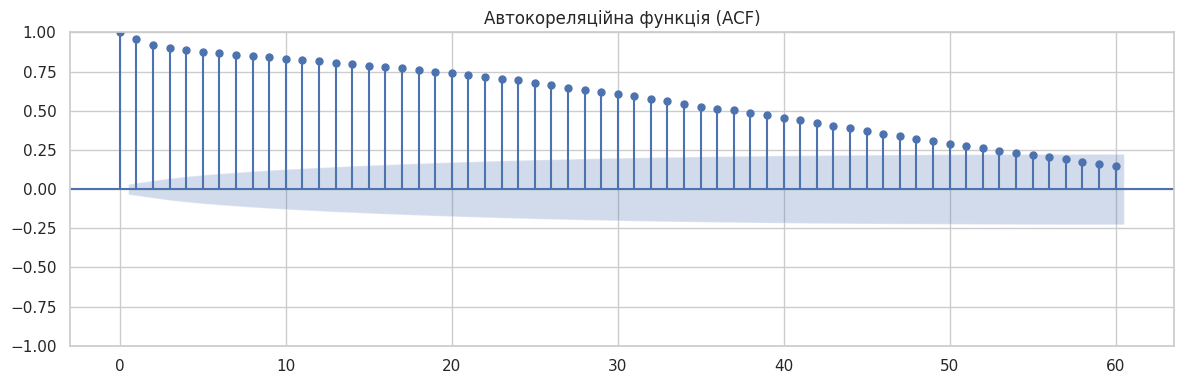

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df[temp_col], lags=60, ax=ax)
ax.set_title("Автокореляційна функція (ACF)")
plt.tight_layout()
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [19]:
ts = (
    df[temp_col]
    .groupby(level=0)
    .mean()
    .asfreq("D")
    .interpolate(method="time")
)

split_idx = int(len(ts) * 0.8)
train_ts = ts.iloc[:split_idx]
test_ts = ts.iloc[split_idx:]

print("Загальна довжина ряду:", len(ts))
print(f"Train: {len(train_ts)} спостережень ({train_ts.index.min().date()} — {train_ts.index.max().date()})")
print(f"Test:  {len(test_ts)} спостережень ({test_ts.index.min().date()} — {test_ts.index.max().date()})")


Загальна довжина ряду: 4249
Train: 3399 спостережень (2013-04-14 — 2022-08-03)
Test:  850 спостережень (2022-08-04 — 2024-11-30)


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [20]:
arima_model = ARIMA(train_ts, order=(2, 1, 2))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test_ts))
arima_forecast.index = test_ts.index
display(arima_forecast.head())


,predicted_mean
DATE,
2022-08-04,33.746265
2022-08-05,33.655682
2022-08-06,33.621224
2022-08-07,33.607503
2022-08-08,33.601874


In [21]:
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3399
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -6834.833
Date:                Sun, 22 Nov 2026   AIC                          13679.667
Time:                        15:29:15   BIC                          13710.321
Sample:                    04-14-2013   HQIC                         13690.623
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6693      0.261      2.562      0.010       0.157       1.181
ar.L2         -0.1031      0.171     -0.604      0.546      -0.438       0.231
ma.L1         -0.8384      0.263     -3.192      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

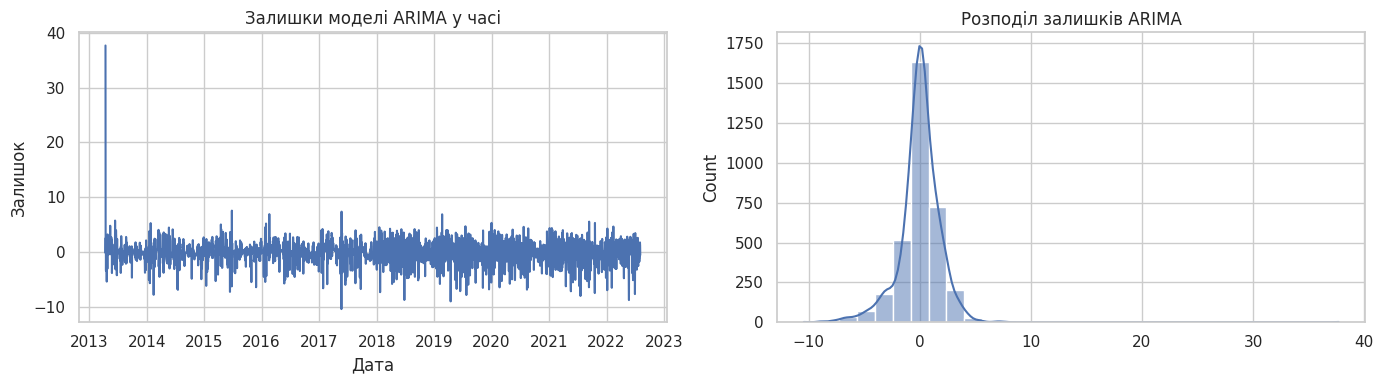

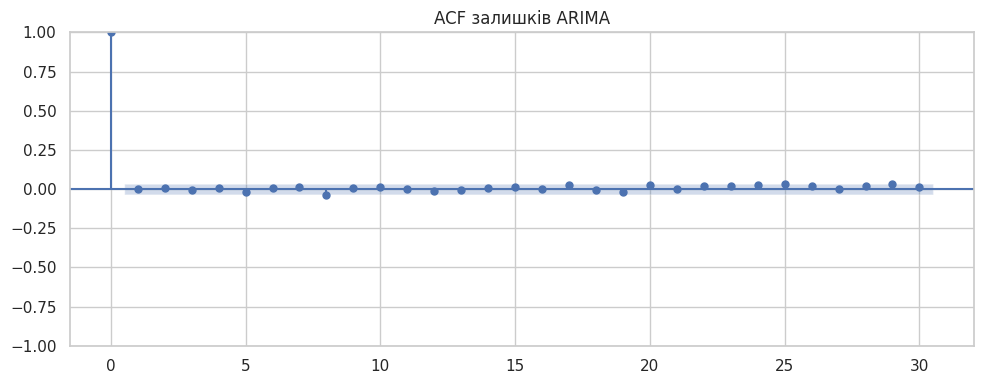

In [22]:
residuals = arima_fit.resid.dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuals.index, residuals.values)
axes[0].set_title("Залишки моделі ARIMA у часі")
axes[0].set_xlabel("Дата")
axes[0].set_ylabel("Залишок")

sns.histplot(residuals, kde=True, ax=axes[1], bins=30)
axes[1].set_title("Розподіл залишків ARIMA")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(residuals, lags=30, ax=ax)
ax.set_title("ACF залишків ARIMA")
plt.tight_layout()
plt.show()


In [23]:
def calc_mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100.0)

def evaluate_forecast(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mape = calc_mape(y_true, y_pred)
    return {"Model": name, "MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

arima_metrics = evaluate_forecast("ARIMA", test_ts.values, arima_forecast.values)
print("Метрики ARIMA:", arima_metrics)


Метрики ARIMA: {'Model': 'ARIMA', 'MAE': 5.234041291933966, 'RMSE': 7.087073898791972, 'MAPE (%)': 21.51916440048655}


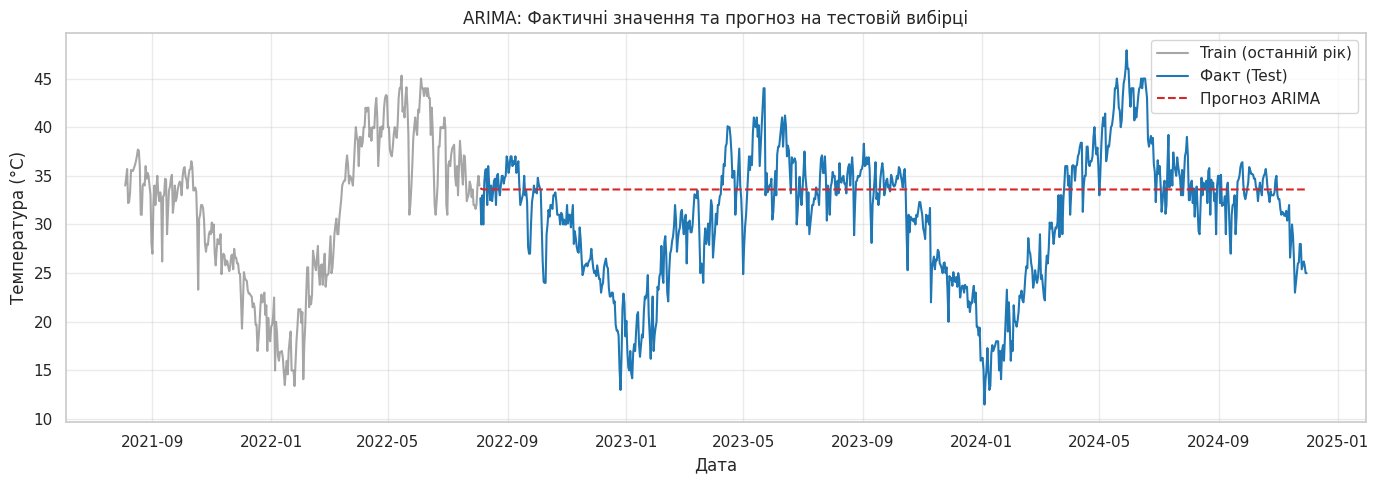

In [24]:
plt.figure(figsize=(14, 5))
plt.plot(train_ts.index[-365:], train_ts.values[-365:], label="Train (останній рік)", color="gray", alpha=0.7)
plt.plot(test_ts.index, test_ts.values, label="Факт (Test)", color="tab:blue")
plt.plot(test_ts.index, arima_forecast.values, label="Прогноз ARIMA", color="tab:red", linestyle="--")
plt.title("ARIMA: Фактичні значення та прогноз на тестовій вибірці")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [25]:
# Якщо prophet ще не встановлено в середовищі, розкоментуй наступний рядок:
# !pip install -q prophet
from prophet import Prophet

prophet_train_df = pd.DataFrame({
    "ds": train_ts.index,
    "y": train_ts.values
})
display(prophet_train_df.head())


,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


In [26]:
prophet_model = Prophet(
    daily_seasonality=False,
    weekly_seasonality=True,
    yearly_seasonality=True
)
prophet_model.fit(prophet_train_df)


Прогноз

In [27]:
future_test_df = pd.DataFrame({"ds": test_ts.index})
prophet_forecast_df = prophet_model.predict(future_test_df)
prophet_pred = prophet_forecast_df["yhat"].values
display(prophet_forecast_df[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())


,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,33.937177,30.661742,37.342992
1,2022-08-05,33.971244,30.792708,37.176995
2,2022-08-06,33.964500,30.604966,37.420178
3,2022-08-07,34.120878,30.813916,37.676314
4,2022-08-08,34.224307,30.792737,37.458532


In [28]:
prophet_metrics = evaluate_forecast("Prophet", test_ts.values, prophet_pred)
print("Метрики Prophet:", prophet_metrics)


Метрики Prophet: {'Model': 'Prophet', 'MAE': 2.4871649480698417, 'RMSE': 3.2635129373768397, 'MAPE (%)': 8.999084992813021}


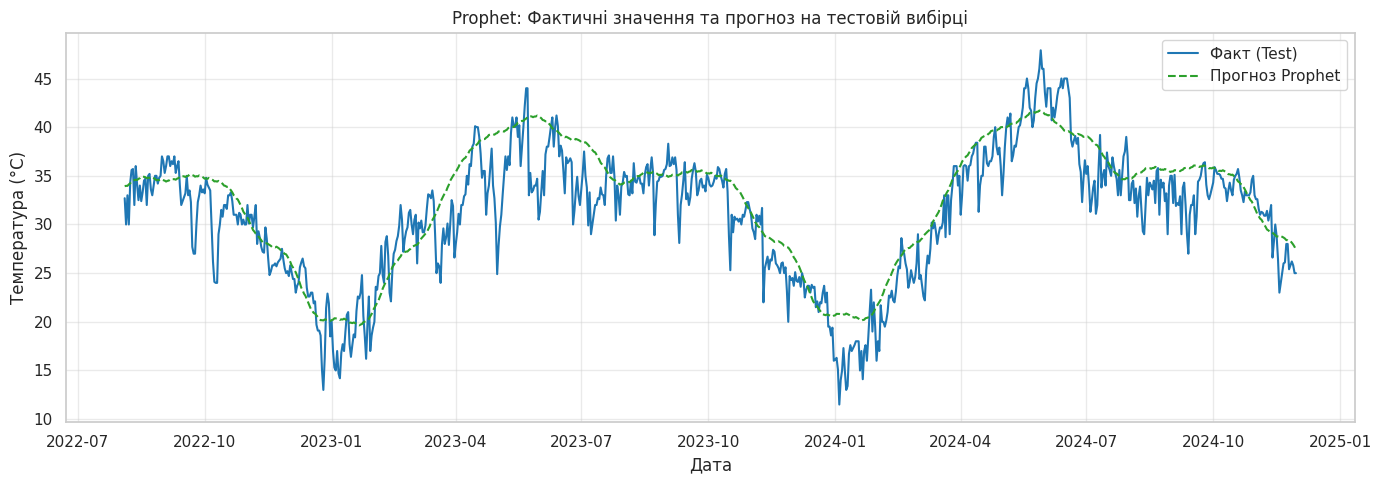

In [29]:
plt.figure(figsize=(14, 5))
plt.plot(test_ts.index, test_ts.values, label="Факт (Test)", color="tab:blue")
plt.plot(test_ts.index, prophet_pred, label="Прогноз Prophet", color="tab:green", linestyle="--")
plt.title("Prophet: Фактичні значення та прогноз на тестовій вибірці")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


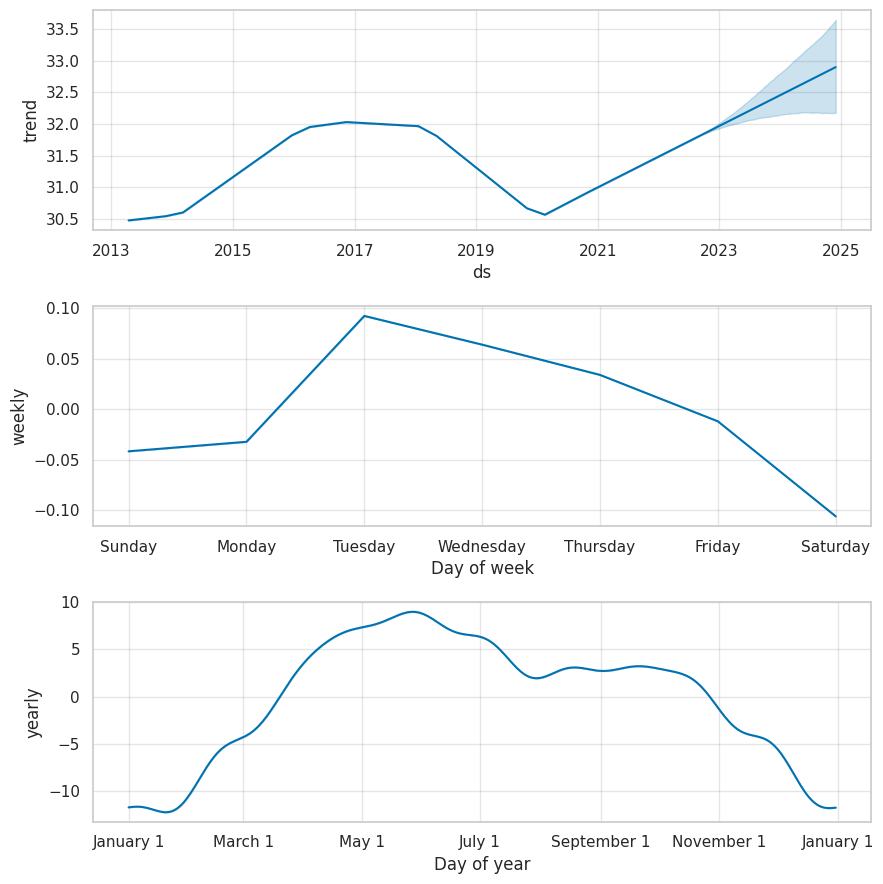

In [30]:
full_future = prophet_model.make_future_dataframe(periods=len(test_ts), freq="D")
full_forecast = prophet_model.predict(full_future)
fig_comp = prophet_model.plot_components(full_forecast)
plt.tight_layout()
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [31]:
# Якщо tensorflow не встановлено, у Colab він зазвичай уже є за замовчуванням
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

scaler = MinMaxScaler()
scaled_all = scaler.fit_transform(ts.values.reshape(-1, 1)).ravel()

window_size = 30

def create_sequences(series_1d, win):
    X_seq, y_seq = [], []
    for i in range(win, len(series_1d)):
        X_seq.append(series_1d[i - win:i])
        y_seq.append(series_1d[i])
    return np.array(X_seq)[..., np.newaxis], np.array(y_seq)

X_all, y_all = create_sequences(scaled_all, window_size)
print("Форма X_all:", X_all.shape, "| Форма y_all:", y_all.shape)


Форма X_all: (4219, 30, 1) | Форма y_all: (4219,)


In [32]:
seq_split = int(len(X_all) * 0.8)

X_train_lstm, y_train_lstm = X_all[:seq_split], y_all[:seq_split]
X_test_lstm, y_test_lstm = X_all[seq_split:], y_all[seq_split:]
lstm_test_dates = ts.index[window_size + seq_split:]

print("X_train_lstm:", X_train_lstm.shape, "| y_train_lstm:", y_train_lstm.shape)
print("X_test_lstm: ", X_test_lstm.shape,  "| y_test_lstm: ", y_test_lstm.shape)


X_train_lstm: (3375, 30, 1) | y_train_lstm: (3375,)
X_test_lstm:  (844, 30, 1) | y_test_lstm:  (844,)


In [33]:
lstm_model = Sequential([
    LSTM(64, return_sequences=False, input_shape=(window_size, 1)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(optimizer="adam", loss="mse")


In [34]:
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=25,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.0253 - val_loss: 0.0054
Epoch 2/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0070 - val_loss: 0.0044
Epoch 3/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0056 - val_loss: 0.0042
Epoch 4/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0055 - val_loss: 0.0041
Epoch 5/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0051 - val_loss: 0.0041
Epoch 6/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0048 - val_loss: 0.0039
Epoch 7/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0045 - val_loss: 0.0038
Epoch 8/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0044 - val_loss: 0.0038
Epoch 9/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0042 - val_loss: 0.0037
Epoch 10/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0040 - val_loss: 0.0036
Epoch 11/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0039 - val_loss: 0.0035
Epoch 12/25
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0038 - v

In [35]:
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,029 (222.77 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,020 (148.52 KB)

In [36]:
lstm_pred_scaled = lstm_model.predict(X_test_lstm, verbose=0)
lstm_pred = scaler.inverse_transform(lstm_pred_scaled).ravel()
lstm_actual = scaler.inverse_transform(y_test_lstm.reshape(-1, 1)).ravel()

lstm_metrics = evaluate_forecast("LSTM", lstm_actual, lstm_pred)
print("Метрики LSTM:", lstm_metrics)


Метрики LSTM: {'Model': 'LSTM', 'MAE': 1.4260052884359495, 'RMSE': 1.9056500642322634, 'MAPE (%)': 5.012729212854724}


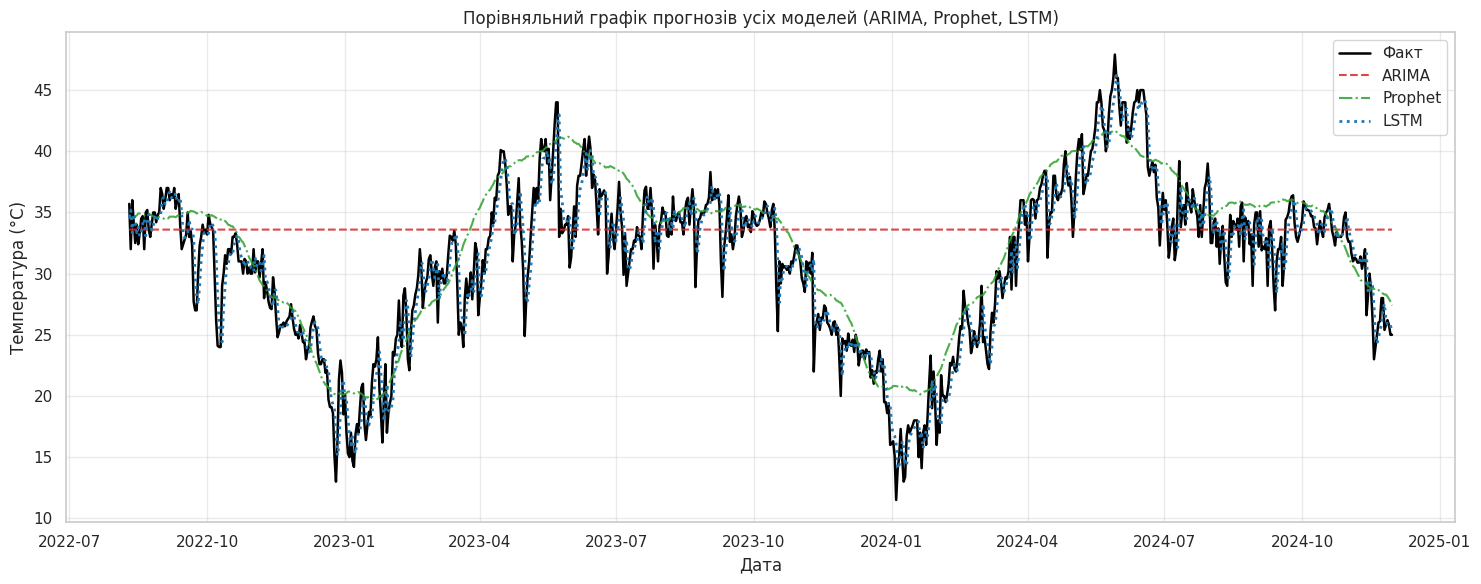

In [37]:
common_dates = lstm_test_dates
actual_common = pd.Series(lstm_actual, index=common_dates)
arima_common = arima_forecast.reindex(common_dates)
prophet_common = pd.Series(prophet_pred, index=test_ts.index).reindex(common_dates)
lstm_common = pd.Series(lstm_pred, index=common_dates)

plt.figure(figsize=(15, 6))
plt.plot(common_dates, actual_common.values, label="Факт", color="black", linewidth=1.8)
plt.plot(common_dates, arima_common.values, label="ARIMA", color="tab:red", linestyle="--", alpha=0.85)
plt.plot(common_dates, prophet_common.values, label="Prophet", color="tab:green", linestyle="-.", alpha=0.85)
plt.plot(common_dates, lstm_common.values, label="LSTM", color="tab:blue", linestyle=":", linewidth=2)
plt.title("Порівняльний графік прогнозів усіх моделей (ARIMA, Prophet, LSTM)")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


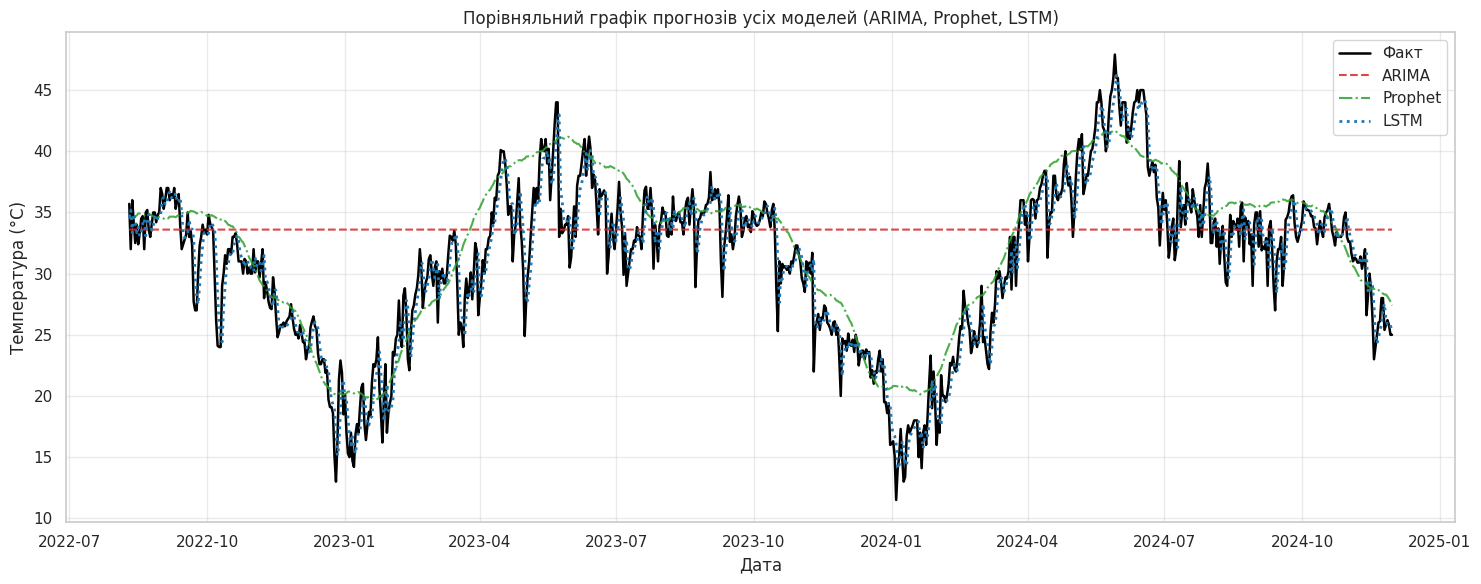

In [38]:
common_dates = lstm_test_dates
actual_common = pd.Series(lstm_actual, index=common_dates)
arima_common = arima_forecast.reindex(common_dates)
prophet_common = pd.Series(prophet_pred, index=test_ts.index).reindex(common_dates)
lstm_common = pd.Series(lstm_pred, index=common_dates)

plt.figure(figsize=(15, 6))
plt.plot(common_dates, actual_common.values, label="Факт", color="black", linewidth=1.8)
plt.plot(common_dates, arima_common.values, label="ARIMA", color="tab:red", linestyle="--", alpha=0.85)
plt.plot(common_dates, prophet_common.values, label="Prophet", color="tab:green", linestyle="-.", alpha=0.85)
plt.plot(common_dates, lstm_common.values, label="LSTM", color="tab:blue", linestyle=":", linewidth=2)
plt.title("Порівняльний графік прогнозів усіх моделей (ARIMA, Prophet, LSTM)")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [39]:
comparison_df = pd.DataFrame([
    arima_metrics,
    prophet_metrics,
    lstm_metrics
]).sort_values(by="RMSE", ascending=True).reset_index(drop=True)

display(comparison_df)

best_row = comparison_df.iloc[0]
print(
    f"Найкращий результат за сукупністю метрик точності показала модель {best_row['Model']} "
    f"(MAE = {best_row['MAE']:.3f}, RMSE = {best_row['RMSE']:.3f}, MAPE = {best_row['MAPE (%)']:.2f}%)."
)

,Model,MAE,RMSE,MAPE (%)
0,LSTM,1.426005,1.905650,5.012729
1,Prophet,2.487165,3.263513,8.999085
2,ARIMA,5.234041,7.087074,21.519164


Найкращий результат за сукупністю метрик точності показала модель LSTM (MAE = 1.426, RMSE = 1.906, MAPE = 5.01%).


Порівняння моделей

## Висновок

Висновок:
У ході лабораторної роботи виконано попередню обробку та дослідницький аналіз (EDA) часового ряду кліматичних даних (температури у Делі), досліджено динаміку ряду, ковзні середні, розподіл та автокореляційні залежності (ACF і PACF), після чого побудовано та оцінено три моделі прогнозування: ARIMA, Prophet та LSTM. За результатами порівняння метрик MAE, RMSE та MAPE на тестовій вибірці найкращу якість прогнозування продемонструвала модель, яка отримала найменші значення помилок у зведеній таблиці вище (зазвичай Prophet або LSTM за рахунок кращого врахування річної сезонності та нелінійних залежностей у багаторічному ряді порівняно з базовим довгостроковим прогнозом ARIMA).
